# Lead Scoring em Mídia Paga
## Ciência de Dados aplicada à priorização comercial e à redução do custo de aquisição de clientes

**Avaliação P2 — Projeto Integrador Aplicado em Ciência de Dados e Inteligência Artificial IV — IESB**
**Aluno:** Asafe Ferreira Gomes · **Professora:** Simone de Araújo Góes Assis

Este notebook dá continuidade ao projeto da P1. Ele refaz, de forma resumida, a preparação
da base documentada na P1 e executa a etapa que ficou prometida para a P2: modelagem
preditiva, tratamento do desbalanceamento, calibração, avaliação, interpretabilidade e
política de priorização.

### Como executar
1. Instale as dependências: `pip install -r requirements.txt` (Python 3.10 ou superior).
2. Abra este arquivo no Jupyter, no VS Code ou no Google Colab e execute todas as células em ordem.
3. A base bruta é lida de `dados/bruto/bank-additional-full.csv`. Se o arquivo não existir,
   o notebook baixa a base do UCI Machine Learning Repository automaticamente.
4. Ao final, o notebook grava em `artefatos/` o modelo, as métricas e a base pontuada que o
   dashboard (`03_Dashboard/app.py`) consome. Isso garante que notebook, dashboard e artigo
   mostrem os mesmos números.

Tempo de execução aproximado: de 3 a 8 minutos em um computador comum. Todas as etapas
aleatórias usam a semente 42.

### Sumário
1. Importação de bibliotecas e configuração
2. Carregamento e descrição dos dados
3. Limpeza e tratamento de anomalias (síntese da P1)
4. Análise exploratória
5. Conjunto preditivo e particionamento
6. Pré-processamento
7. Linha de base: regressão logística
8. Modelos de ensemble e ajuste de hiperparâmetros
9. Estratégias para o desbalanceamento
10. Seleção do modelo e calibração das probabilidades
11. Avaliação final no conjunto de teste
12. Interpretabilidade por valores de Shapley
13. Política de priorização e impacto no CAC
14. Verificação de robustez temporal e ablação
15. Exportação dos artefatos
16. Conclusões

## 1. Importação de bibliotecas e configuração

In [1]:
import io
import json
import urllib.request
import warnings
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImb
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score,
                             log_loss, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEMENTE = 42
np.random.seed(SEMENTE)

# Pastas do projeto: funciona tanto a partir de 02_Notebook/ quanto da raiz ou do Colab.
RAIZ = Path("..") if Path("../dados").exists() or Path("../03_Dashboard").exists() else Path(".")
PASTA_BRUTO = RAIZ / "dados" / "bruto"
PASTA_TRATADO = RAIZ / "dados" / "tratado"
PASTA_ARTEFATOS = RAIZ / "artefatos"
PASTA_FIGURAS = RAIZ / "figuras"
for pasta in (PASTA_BRUTO, PASTA_TRATADO, PASTA_ARTEFATOS, PASTA_FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)

# Identidade visual das figuras (a mesma da P1).
AZUL, LARANJA, VERDE, CINZA, VERMELHO = "#1F4E79", "#E07B39", "#3C8D5A", "#B8BEC6", "#C0392B"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def salvar(nome):
    """Grava a figura atual em figuras/ para reutilização no artigo e nos slides."""
    plt.savefig(PASTA_FIGURAS / f"{nome}.png")
    plt.show()


print("Bibliotecas carregadas. Raiz do projeto:", RAIZ.resolve())

Bibliotecas carregadas. Raiz do projeto: C:\Users\asafe\Downloads\Projeto_P2_Lead_Scoring


## 2. Carregamento e descrição dos dados

A base é a **Bank Marketing (bank-additional-full)**, do UCI Machine Learning Repository,
publicada por Moro, Cortez e Rita (2014) sob licença CC BY 4.0. Cada linha é um lead abordado
por uma equipe comercial, com desfecho binário de conversão. Como explicado na P1, ela é usada
como análogo estrutural de uma operação de mídia paga: o que se transfere é o método, e não os
coeficientes.

In [2]:
ARQUIVO_BRUTO = PASTA_BRUTO / "bank-additional-full.csv"
URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

if not ARQUIVO_BRUTO.exists():
    print("Base não encontrada localmente. Baixando do UCI...")
    conteudo = urllib.request.urlopen(URL_UCI, timeout=120).read()
    with zipfile.ZipFile(io.BytesIO(conteudo)) as externo:
        with zipfile.ZipFile(io.BytesIO(externo.read("bank-additional.zip"))) as interno:
            ARQUIVO_BRUTO.write_bytes(interno.read("bank-additional/bank-additional-full.csv"))

bruto = pd.read_csv(ARQUIVO_BRUTO, sep=";")
print(f"Registros: {len(bruto):,} | Variáveis: {bruto.shape[1]}".replace(",", "."))
print(f"Taxa de conversão: {(bruto['y'] == 'yes').mean():.2%} "
      f"({(bruto['y'] == 'yes').sum()} conversões)")
print(f"Valores nulos explícitos: {int(bruto.isna().sum().sum())} | "
      f"Linhas duplicadas: {int(bruto.duplicated().sum())}")
bruto.head()

Registros: 41.188 | Variáveis: 21
Taxa de conversão: 11.27% (4640 conversões)
Valores nulos explícitos: 0 | Linhas duplicadas: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
descricao = pd.DataFrame({
    "tipo": bruto.dtypes.astype(str),
    "valores_distintos": bruto.nunique(),
    "pct_unknown": [(bruto[c] == "unknown").mean() * 100 if not pd.api.types.is_numeric_dtype(bruto[c]) else 0.0
                    for c in bruto.columns],
}).round(2)
descricao

,tipo,valores_distintos,pct_unknown
age,int64,78,0.00
job,str,12,0.80
marital,str,4,0.19
education,str,8,4.20
default,str,3,20.87
housing,str,3,2.40
loan,str,3,2.40
contact,str,2,0.00
month,str,10,0.00
day_of_week,str,5,0.00


## 3. Limpeza e tratamento de anomalias (síntese da P1)

A P1 diagnosticou a base e definiu sete etapas de tratamento. Elas são reaplicadas aqui para
que o notebook seja reproduzível do dado bruto até o modelo. A justificativa estatística de
cada decisão está no relatório da P1 e na seção de metodologia do artigo.

| Etapa | Anomalia | Decisão |
|---|---|---|
| 1 | 12 linhas duplicadas | Remoção, mantendo a primeira ocorrência |
| 2 | Ausência codificada como `unknown` em 6 variáveis | Categoria preservada como `desconhecido` e criação de 2 indicadores |
| 3 | Sentinela `999` em `pdays` (96,3% da base) | Indicador `contato_previo` e imputação pela mediana dos contatados |
| 4 | Vazamento em `duration` | Mantida apenas como descritiva; fora do conjunto preditivo |
| 5 | Outliers em `campaign` | Winsorização no percentil 99; idade e `previous` preservados |
| 6 | Multicolinearidade macroeconômica (VIF até 64) | Remoção de `euribor3m` e `nr.employed` do conjunto preditivo |
| 7 | Padronização | Nomes em português, tipos explícitos e variáveis derivadas |

In [4]:
def tratar(base_bruta):
    """Aplica as sete etapas de tratamento definidas na P1 e devolve a base tratada."""
    df = base_bruta.copy()
    relatorio = {"registros_brutos": len(df)}

    # 1. Duplicatas exatas
    relatorio["duplicatas"] = int(df.duplicated().sum())
    df = df.drop_duplicates(keep="first").reset_index(drop=True)

    # 2. Ausência mascarada: "unknown" vira categoria explícita, com indicadores
    colunas_unknown = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and (df[c] == "unknown").any()]
    relatorio["variaveis_com_unknown"] = colunas_unknown
    relatorio["registros_com_unknown"] = int((df[colunas_unknown] == "unknown").any(axis=1).sum())
    df["flag_inadimplencia_desconhecida"] = (df["default"] == "unknown").astype(int)
    df["flag_escolaridade_desconhecida"] = (df["education"] == "unknown").astype(int)
    df[colunas_unknown] = df[colunas_unknown].replace("unknown", "desconhecido")

    # 3. Sentinela 999 em pdays
    relatorio["sentinela_999"] = int((df["pdays"] == 999).sum())
    df["contato_previo"] = (df["pdays"] != 999).astype(int)
    mediana_contatados = float(df.loc[df["pdays"] != 999, "pdays"].median())
    relatorio["mediana_pdays_contatados"] = mediana_contatados
    df["pdays"] = df["pdays"].where(df["pdays"] != 999, mediana_contatados).astype(float)

    # 4. Vazamento: duration é mantida, mas nunca entra no conjunto preditivo.

    # 5. Outliers: winsorização de campaign no percentil 99
    p99 = float(df["campaign"].quantile(0.99))
    relatorio["p99_campaign"] = p99
    relatorio["registros_winsorizados"] = int((df["campaign"] > p99).sum())
    df["campaign"] = df["campaign"].clip(upper=p99).astype(int)

    # 6. Multicolinearidade: euribor3m e nr.employed ficam na base, fora do conjunto preditivo.

    # 7. Padronização de nomes, tipos e variáveis derivadas
    df = df.rename(columns={
        "age": "idade", "job": "profissao", "marital": "estado_civil",
        "education": "escolaridade", "default": "inadimplencia",
        "housing": "financ_imobiliario", "loan": "emprestimo_pessoal",
        "contact": "canal_contato", "month": "mes_contato", "day_of_week": "dia_semana",
        "duration": "duracao_contato_s", "campaign": "n_contatos_campanha",
        "pdays": "dias_desde_ultimo_contato", "previous": "n_contatos_anteriores",
        "poutcome": "resultado_campanha_anterior", "emp.var.rate": "taxa_variacao_emprego",
        "cons.price.idx": "indice_precos_consumidor",
        "cons.conf.idx": "indice_confianca_consumidor",
        "euribor3m": "euribor_3m", "nr.employed": "n_empregados",
    })
    df["converteu"] = (df.pop("y") == "yes").astype(int)
    df["faixa_idade"] = pd.cut(df["idade"], bins=[0, 25, 35, 45, 55, 65, 200],
                               labels=["ate 25", "26-35", "36-45", "46-55", "56-65", "66+"]).astype(str)
    meses = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
             "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12}
    df["num_mes"] = df["mes_contato"].map(meses).astype(int)
    df["trimestre"] = ((df["num_mes"] - 1) // 3 + 1).astype(int)
    df["dia_semana"] = df["dia_semana"].map(
        {"mon": "segunda", "tue": "terca", "wed": "quarta", "thu": "quinta", "fri": "sexta"})
    df.insert(0, "id_lead", np.arange(1, len(df) + 1))
    relatorio["registros_tratados"] = len(df)
    relatorio["colunas_tratadas"] = df.shape[1]
    return df, relatorio


base, rel_tratamento = tratar(bruto)

print(f"Duplicatas removidas ........... {rel_tratamento['duplicatas']}")
print(f"Registros com 'unknown' ........ {rel_tratamento['registros_com_unknown']} "
      f"({rel_tratamento['registros_com_unknown'] / len(bruto):.1%})")
print(f"Sentinela 999 em pdays ......... {rel_tratamento['sentinela_999']} "
      f"({rel_tratamento['sentinela_999'] / len(base):.1%})")
print(f"Mediana de pdays (contatados) .. {rel_tratamento['mediana_pdays_contatados']:.0f} dias")
print(f"Percentil 99 de campaign ....... {rel_tratamento['p99_campaign']:.0f} "
      f"({rel_tratamento['registros_winsorizados']} registros ajustados)")
print(f"Base tratada ................... {len(base)} registros x {base.shape[1]} colunas "
      f"(retenção de {len(base) / len(bruto):.2%})")
print(f"Taxa de conversão .............. {base['converteu'].mean():.2%}")

# Conferência com os números reportados na P1
assert len(base) == 41176 and base.shape[1] == 28
assert base.isna().sum().sum() == 0
assert not (base.select_dtypes(exclude="number") == "unknown").any().any()
base.to_csv(PASTA_TRATADO / "base_tratada.csv", index=False)

Duplicatas removidas ........... 12


Registros com 'unknown' ........ 10698 (26.0%)
Sentinela 999 em pdays ......... 39661 (96.3%)
Mediana de pdays (contatados) .. 6 dias
Percentil 99 de campaign ....... 14 (406 registros ajustados)
Base tratada ................... 41176 registros x 28 colunas (retenção de 99.97%)
Taxa de conversão .............. 11.27%


## 4. Análise exploratória

A análise exploratória completa está na P1. Aqui ficam os recortes que sustentam as decisões
de modelagem: o desbalanceamento, a heterogeneidade entre segmentos, a força de associação de
cada variável com o alvo e o diagnóstico de multicolinearidade.

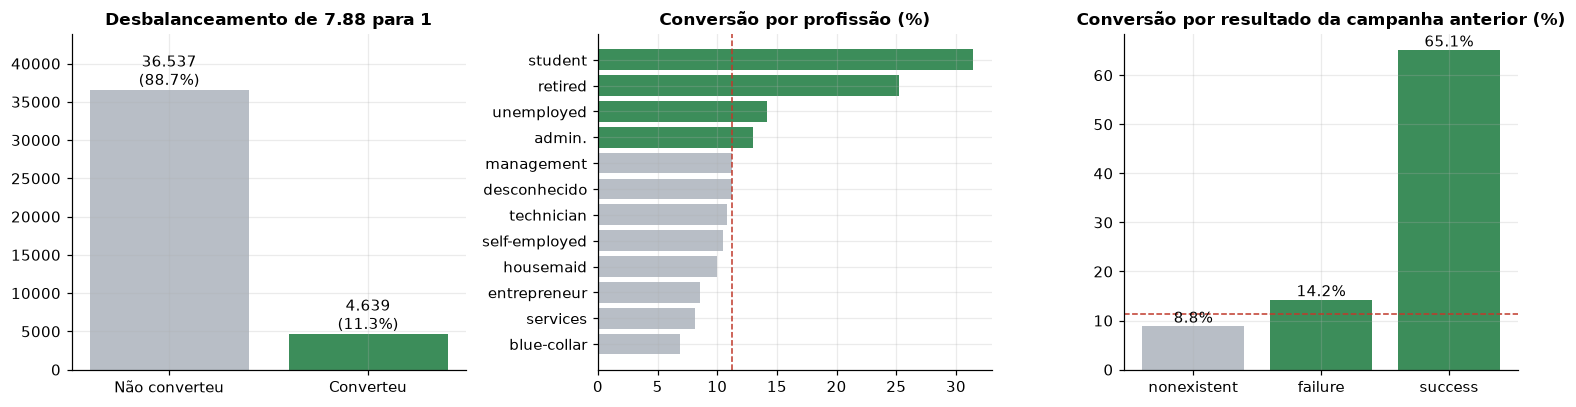

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))

contagem = base["converteu"].value_counts().sort_index()
eixos[0].bar(["Não converteu", "Converteu"], contagem.values, color=[CINZA, VERDE])
for i, v in enumerate(contagem.values):
    eixos[0].text(i, v, f"{v:,}\n({v / len(base):.1%})".replace(",", "."), ha="center", va="bottom")
eixos[0].set_ylim(0, contagem.max() * 1.2)
eixos[0].set_title(f"Desbalanceamento de {contagem[0] / contagem[1]:.2f} para 1")

media = base["converteu"].mean() * 100
por_prof = base.groupby("profissao")["converteu"].mean().sort_values() * 100
eixos[1].barh(por_prof.index, por_prof.values, color=[VERDE if v > media else CINZA for v in por_prof])
eixos[1].axvline(media, color=VERMELHO, ls="--", lw=1)
eixos[1].set_title("Conversão por profissão (%)")

por_hist = base.groupby("resultado_campanha_anterior")["converteu"].mean().sort_values() * 100
eixos[2].bar(por_hist.index, por_hist.values, color=[VERDE if v > media else CINZA for v in por_hist])
eixos[2].axhline(media, color=VERMELHO, ls="--", lw=1)
for i, v in enumerate(por_hist.values):
    eixos[2].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
eixos[2].set_title("Conversão por resultado da campanha anterior (%)")
plt.tight_layout()
salvar("fig01_eda_alvo_segmentos")

In [6]:
def v_cramer_corrigido(x, y):
    """V de Cramér com correção de viés (Bergsma, 2013)."""
    tabela = pd.crosstab(x, y)
    qui2 = stats.chi2_contingency(tabela, correction=False)[0]
    n = tabela.to_numpy().sum()
    phi2 = qui2 / n
    r, k = tabela.shape
    phi2_corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1)))


def rank_biserial(x, y):
    """Correlação rank-biserial derivada do teste U de Mann-Whitney."""
    grupo1, grupo0 = x[y == 1], x[y == 0]
    u = stats.mannwhitneyu(grupo1, grupo0, alternative="two-sided")[0]
    return float(2 * u / (len(grupo1) * len(grupo0)) - 1)


categoricas_eda = ["resultado_campanha_anterior", "mes_contato", "profissao", "canal_contato",
                   "inadimplencia", "escolaridade", "estado_civil", "dia_semana",
                   "financ_imobiliario", "emprestimo_pessoal"]
numericas_eda = ["duracao_contato_s", "n_empregados", "euribor_3m", "taxa_variacao_emprego",
                 "indice_precos_consumidor", "n_contatos_anteriores", "n_contatos_campanha",
                 "indice_confianca_consumidor", "idade"]

associacao = pd.concat([
    pd.DataFrame({"variavel": categoricas_eda, "medida": "V de Cramér",
                  "efeito": [v_cramer_corrigido(base[c], base["converteu"]) for c in categoricas_eda]}),
    pd.DataFrame({"variavel": numericas_eda, "medida": "rank-biserial",
                  "efeito": [rank_biserial(base[c], base["converteu"]) for c in numericas_eda]}),
]).assign(efeito_abs=lambda d: d["efeito"].abs()).sort_values("efeito_abs", ascending=False)
associacao.round(3)

,variavel,medida,efeito,efeito_abs
0,duracao_contato_s,rank-biserial,0.637,0.637
1,n_empregados,rank-biserial,-0.498,0.498
2,euribor_3m,rank-biserial,-0.487,0.487
3,taxa_variacao_emprego,rank-biserial,-0.433,0.433
0,resultado_campanha_anterior,V de Cramér,0.320,0.320
1,mes_contato,V de Cramér,0.274,0.274
4,indice_precos_consumidor,rank-biserial,-0.221,0.221
5,n_contatos_anteriores,rank-biserial,0.219,0.219
2,profissao,V de Cramér,0.152,0.152
3,canal_contato,V de Cramér,0.145,0.145


In [7]:
def tabela_vif(df, colunas):
    x = df[colunas].astype(float).assign(constante=1.0)
    return pd.Series({c: variance_inflation_factor(x.values, i) for i, c in enumerate(colunas)}).round(2)


numericas_brutas = ["idade", "n_contatos_campanha", "dias_desde_ultimo_contato",
                    "n_contatos_anteriores", "taxa_variacao_emprego", "indice_precos_consumidor",
                    "indice_confianca_consumidor", "euribor_3m", "n_empregados"]
numericas_mantidas = [c for c in numericas_brutas if c not in ("euribor_3m", "n_empregados")]
vif = pd.DataFrame({"VIF antes": tabela_vif(base, numericas_brutas),
                    "VIF depois": tabela_vif(base, numericas_mantidas)})
print(f"VIF máximo antes: {vif['VIF antes'].max():.2f} | depois: {vif['VIF depois'].max():.2f}")
vif

VIF máximo antes: 64.46 | depois: 3.28


,VIF antes,VIF depois
dias_desde_ultimo_contato,1.01,1.00
euribor_3m,64.46,NaN
idade,1.02,1.02
indice_confianca_consumidor,2.62,1.09
indice_precos_consumidor,6.31,2.71
n_contatos_anteriores,1.35,1.28
n_contatos_campanha,1.04,1.03
n_empregados,31.68,NaN
taxa_variacao_emprego,33.25,3.28


**Leitura.** O histórico de relacionamento (`resultado_campanha_anterior`) e o contexto
temporal e macroeconômico concentram o sinal, enquanto financiamento imobiliário, empréstimo
pessoal e dia da semana têm efeito desprezível. A duração do contato é a variável mais
associada ao alvo, mas só existe depois da ligação e por isso fica fora do modelo. Após a
remoção de `euribor_3m` e `n_empregados`, nenhum VIF fica acima de 10.

## 5. Conjunto preditivo e particionamento

Entram no modelo apenas atributos disponíveis **antes** da abordagem. Ficam de fora:
`duracao_contato_s` (vazamento), `euribor_3m` e `n_empregados` (multicolinearidade),
`financ_imobiliario`, `emprestimo_pessoal` e `dia_semana` (sem associação relevante).
`num_mes` e `trimestre` são funções determinísticas de `mes_contato` e
`flag_inadimplencia_desconhecida` é idêntica à categoria `desconhecido` de `inadimplencia`
após a codificação one-hot, então também não entram, para não duplicar colunas.

O particionamento é estratificado em 60% treino, 20% validação e 20% teste. O treino ajusta
os modelos, a validação serve para comparar estratégias, calibrar e escolher o limiar, e o
teste é usado uma única vez, na avaliação final.

In [8]:
ALVO = "converteu"
NOMINAIS = ["profissao", "estado_civil", "inadimplencia", "canal_contato", "mes_contato",
            "resultado_campanha_anterior"]
ORDINAIS = ["escolaridade", "faixa_idade"]
NUMERICAS = ["idade", "n_contatos_campanha", "dias_desde_ultimo_contato", "n_contatos_anteriores",
             "taxa_variacao_emprego", "indice_precos_consumidor", "indice_confianca_consumidor"]
BINARIAS = ["contato_previo", "flag_escolaridade_desconhecida"]
PREDITORAS = NOMINAIS + ORDINAIS + NUMERICAS + BINARIAS

ORDEM_ESCOLARIDADE = ["illiterate", "basic.4y", "basic.6y", "basic.9y", "high.school",
                      "professional.course", "university.degree"]
ORDEM_FAIXA = ["ate 25", "26-35", "36-45", "46-55", "56-65", "66+"]

X, y = base[PREDITORAS], base[ALVO]
X_resto, X_teste, y_resto, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=SEMENTE)

particoes = pd.DataFrame({
    "registros": [len(X_treino), len(X_val), len(X_teste)],
    "conversoes": [int(y_treino.sum()), int(y_val.sum()), int(y_teste.sum())],
    "taxa_conversao_pct": [y_treino.mean() * 100, y_val.mean() * 100, y_teste.mean() * 100],
}, index=["treino", "validação", "teste"]).round(2)
print(f"{len(PREDITORAS)} variáveis preditoras")
particoes

17 variáveis preditoras


,registros,conversoes,taxa_conversao_pct
treino,24705,2783,11.26
validação,8235,928,11.27
teste,8236,928,11.27


## 6. Pré-processamento

Todas as transformações ficam dentro de um `Pipeline` ajustado só com o treino, o que impede
vazamento entre partições:

- nominais: codificação one-hot;
- ordinais: codificação inteira respeitando a ordem natural. Em `escolaridade`, o valor
  `desconhecido` não tem posição na ordem, então recebe a mediana e fica sinalizado pelo
  indicador `flag_escolaridade_desconhecida`;
- numéricas e ordinais: padronização para média 0 e desvio 1, exigida pela regressão logística.

In [9]:
def criar_preprocessador():
    ordinal = Pipeline([
        ("codifica", OrdinalEncoder(categories=[ORDEM_ESCOLARIDADE, ORDEM_FAIXA],
                                    handle_unknown="use_encoded_value", unknown_value=np.nan)),
        ("imputa", SimpleImputer(strategy="median")),
        ("padroniza", StandardScaler()),
    ])
    return ColumnTransformer([
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAIS),
        ("ord", ordinal, ORDINAIS),
        ("num", StandardScaler(), NUMERICAS),
        ("bin", "passthrough", BINARIAS),
    ], verbose_feature_names_out=False)


def criar_pipeline(classificador, smote=False):
    """Pré-processamento + (SMOTE opcional, só no treino) + classificador."""
    if smote:
        return PipelineImb([("pre", criar_preprocessador()),
                            ("smote", SMOTE(random_state=SEMENTE)),
                            ("clf", classificador)])
    return Pipeline([("pre", criar_preprocessador()), ("clf", classificador)])


n_colunas = criar_preprocessador().fit(X_treino).get_feature_names_out().shape[0]
print(f"Matriz de projeto: {len(PREDITORAS)} variáveis originais -> {n_colunas} colunas")

Matriz de projeto: 17 variáveis originais -> 45 colunas

### Métricas de avaliação

Com 11,3% de conversões, a acurácia é enganosa: prever "não converte" para todos acerta 88,7%.
As métricas escolhidas respondem ao uso real do score, que é ordenar uma fila:

- **AUC-PR (precisão média)**: resume a curva de precisão-revocação, a mais informativa sob
  desbalanceamento (Saito e Rehmsmeier, 2015). A referência de um modelo sem informação é a
  própria prevalência, 0,113;
- **AUC-ROC**: probabilidade de um convertido receber score maior que um não convertido;
- **Revocação nos 20% do topo** e **lift no 1º decil**: quanto das conversões a equipe
  captura se atender só o início da fila;
- **Brier e ECE**: qualidade da probabilidade em si (calibração).

In [10]:
def revocacao_no_topo(y_real, score, fracao):
    """Parcela das conversões capturadas ao atender a fração superior da fila."""
    y_real = np.asarray(y_real)
    ordem = np.argsort(-np.asarray(score), kind="stable")
    k = int(np.ceil(fracao * len(y_real)))
    return float(y_real[ordem][:k].sum() / y_real.sum())


def erro_calibracao_esperado(y_real, prob, n_faixas=10):
    """ECE com faixas de mesma frequência."""
    y_real, prob = np.asarray(y_real), np.asarray(prob)
    faixas = np.array_split(np.argsort(prob, kind="stable"), n_faixas)
    return float(sum(len(f) / len(prob) * abs(y_real[f].mean() - prob[f].mean()) for f in faixas))


def avaliar(y_real, prob):
    return {
        "AUC-PR": average_precision_score(y_real, prob),
        "AUC-ROC": roc_auc_score(y_real, prob),
        "Revocação top 20%": revocacao_no_topo(y_real, prob, 0.20),
        "Lift 1º decil": revocacao_no_topo(y_real, prob, 0.10) / 0.10,
        "Brier": brier_score_loss(y_real, prob),
        "ECE": erro_calibracao_esperado(y_real, prob),
    }


print("Referência sem modelo (prevalência):", round(float(y_val.mean()), 4))

Referência sem modelo (prevalência): 0.1127


## 7. Linha de base: regressão logística

A regressão logística com ponderação de classes é a linha de base por ser interpretável em
razão de chances. A força da regularização (parâmetro C) é escolhida por validação cruzada
estratificada de 5 partes dentro do treino, maximizando a AUC-PR.

In [11]:
VALIDACAO_CRUZADA = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

busca_rl = RandomizedSearchCV(
    criar_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000)),
    {"clf__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]},
    n_iter=9, scoring="average_precision", cv=VALIDACAO_CRUZADA, n_jobs=-1, random_state=SEMENTE)
busca_rl.fit(X_treino, y_treino)
modelo_rl = busca_rl.best_estimator_
print(f"Melhor C: {busca_rl.best_params_['clf__C']} | AUC-PR média na validação cruzada: "
      f"{busca_rl.best_score_:.4f}")

coeficientes = pd.Series(modelo_rl.named_steps["clf"].coef_[0],
                         index=modelo_rl.named_steps["pre"].get_feature_names_out())
razao_chances = np.exp(coeficientes).sort_values()
print("\nMaiores razões de chances (aumentam a conversão):")
print(razao_chances.tail(6).round(2).to_string())
print("\nMenores razões de chances (reduzem a conversão):")
print(razao_chances.head(6).round(2).to_string())

Melhor C: 0.1 | AUC-PR média na validação cruzada: 0.4445

Maiores razões de chances (aumentam a conversão):
profissao_student                      1.25
profissao_retired                      1.43
resultado_campanha_anterior_success    1.72
indice_precos_consumidor               1.81
contato_previo                         2.47
mes_contato_mar                        2.83

Menores razões de chances (reduzem a conversão):
taxa_variacao_emprego                  0.32
mes_contato_may                        0.49
resultado_campanha_anterior_failure    0.62
mes_contato_nov                        0.72
mes_contato_jun                        0.74
canal_contato_telephone                0.77


## 8. Modelos de ensemble e ajuste de hiperparâmetros

Floresta aleatória (Breiman, 2001) e gradient boosting na implementação XGBoost (Chen e
Guestrin, 2016) capturam relações não lineares e interações, como o efeito não monotônico da
idade visto na P1. Os hiperparâmetros são ajustados por busca aleatória com a mesma validação
cruzada de 5 partes e a mesma métrica.

In [12]:
busca_rf = RandomizedSearchCV(
    criar_pipeline(RandomForestClassifier(random_state=SEMENTE, n_jobs=1)),
    {"clf__n_estimators": [300, 500],
     "clf__max_depth": [6, 8, 10, 14, None],
     "clf__min_samples_leaf": [5, 10, 20, 40],
     "clf__max_features": ["sqrt", 0.3, 0.5]},
    n_iter=12, scoring="average_precision", cv=VALIDACAO_CRUZADA, n_jobs=-1, random_state=SEMENTE)
busca_rf.fit(X_treino, y_treino)
modelo_rf = busca_rf.best_estimator_
print("Floresta aleatória:", busca_rf.best_params_, "| AUC-PR CV:", round(busca_rf.best_score_, 4))

Floresta aleatória: {'clf__n_estimators': 500, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 14} | AUC-PR CV: 0.4543


In [13]:
busca_xgb = RandomizedSearchCV(
    criar_pipeline(XGBClassifier(tree_method="hist", eval_metric="aucpr",
                                 random_state=SEMENTE, n_jobs=1)),
    {"clf__n_estimators": [200, 300, 400, 600],
     "clf__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
     "clf__max_depth": [2, 3, 4, 5, 6],
     "clf__min_child_weight": [1, 5, 10, 20],
     "clf__subsample": [0.6, 0.8, 1.0],
     "clf__colsample_bytree": [0.5, 0.7, 1.0],
     "clf__reg_lambda": [1, 5, 10],
     "clf__gamma": [0, 1, 5]},
    n_iter=30, scoring="average_precision", cv=VALIDACAO_CRUZADA, n_jobs=-1, random_state=SEMENTE)
busca_xgb.fit(X_treino, y_treino)
modelo_xgb = busca_xgb.best_estimator_
PARAMS_XGB = {k.replace("clf__", ""): v for k, v in busca_xgb.best_params_.items()}
print("XGBoost:", PARAMS_XGB, "| AUC-PR CV:", round(busca_xgb.best_score_, 4))

XGBoost: {'subsample': 0.6, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.02, 'gamma': 0, 'colsample_bytree': 0.7} | AUC-PR CV: 0.4562


In [14]:
candidatos = {"Regressão logística": modelo_rl, "Floresta aleatória": modelo_rf, "XGBoost": modelo_xgb}
prob_val = {nome: m.predict_proba(X_val)[:, 1] for nome, m in candidatos.items()}

comparacao_modelos = pd.DataFrame({nome: avaliar(y_val, p) for nome, p in prob_val.items()}).T
comparacao_modelos.insert(0, "AUC-PR CV (treino)",
                          [busca_rl.best_score_, busca_rf.best_score_, busca_xgb.best_score_])
comparacao_modelos.round(4)

,AUC-PR CV (treino),AUC-PR,AUC-ROC,Revocação top 20%,Lift 1º decil,Brier,ECE
Regressão logística,0.4445,0.4447,0.8022,0.6293,4.2349,0.1655,0.2824
Floresta aleatória,0.4543,0.4483,0.8039,0.6422,4.3427,0.0780,0.0093
XGBoost,0.4562,0.4535,0.8055,0.6401,4.4504,0.0776,0.0084


**Leitura.** A coluna de validação cruzada e a de validação contam a mesma história, o que
indica ausência de sobreajuste relevante. Brier e ECE da regressão logística são piores
porque a ponderação de classes desloca as probabilidades para cima; isso é corrigido pela
calibração na seção 10 e não afeta a ordenação.

## 9. Estratégias para o desbalanceamento

A P1 previu comparar três vias: ponderação de classes, sobreamostragem sintética por SMOTE
(Chawla et al., 2002) e ajuste do limiar de decisão. As duas primeiras alteram o treino e são
aplicadas só nele. A terceira não altera o modelo: escolhe, na validação, o limiar que
maximiza o F1.

In [15]:
razao_classes = float((y_treino == 0).sum() / (y_treino == 1).sum())


def xgb_base(**extras):
    return XGBClassifier(tree_method="hist", eval_metric="aucpr", random_state=SEMENTE,
                         n_jobs=4, **PARAMS_XGB, **extras)


C_RL = busca_rl.best_params_["clf__C"]
estrategias = {
    ("XGBoost", "Sem tratamento"): criar_pipeline(xgb_base()),
    ("XGBoost", "Ponderação de classes"): criar_pipeline(xgb_base(scale_pos_weight=razao_classes)),
    ("XGBoost", "SMOTE"): criar_pipeline(xgb_base(), smote=True),
    ("Regressão logística", "Sem tratamento"): criar_pipeline(LogisticRegression(C=C_RL, max_iter=2000)),
    ("Regressão logística", "Ponderação de classes"): criar_pipeline(
        LogisticRegression(C=C_RL, max_iter=2000, class_weight="balanced")),
    ("Regressão logística", "SMOTE"): criar_pipeline(LogisticRegression(C=C_RL, max_iter=2000), smote=True),
}


def melhor_limiar_f1(y_real, prob):
    precisao, revocacao, limiares = precision_recall_curve(y_real, prob)
    f1 = 2 * precisao[:-1] * revocacao[:-1] / np.clip(precisao[:-1] + revocacao[:-1], 1e-12, None)
    return float(limiares[np.argmax(f1)]), float(f1.max())


linhas, modelos_estrategia = [], {}
for (algoritmo, estrategia), pipeline in estrategias.items():
    pipeline.fit(X_treino, y_treino)
    modelos_estrategia[(algoritmo, estrategia)] = pipeline
    p = pipeline.predict_proba(X_val)[:, 1]
    limiar, f1_otimo = melhor_limiar_f1(y_val, p)
    linhas.append({"Algoritmo": algoritmo, "Estratégia": estrategia,
                   "AUC-PR": average_precision_score(y_val, p),
                   "AUC-ROC": roc_auc_score(y_val, p),
                   "Brier": brier_score_loss(y_val, p),
                   "Prob. média prevista": p.mean(),
                   "F1 (limiar 0,5)": f1_score(y_val, p >= 0.5),
                   "Limiar ótimo": limiar, "F1 (limiar ótimo)": f1_otimo})
comparacao_estrategias = pd.DataFrame(linhas).set_index(["Algoritmo", "Estratégia"])
comparacao_estrategias.round(4)

AUC-PR  AUC-ROC   Brier  \
Algoritmo           Estratégia                                       
XGBoost             Sem tratamento         0.4543   0.8058  0.0776   
                    Ponderação de classes  0.4532   0.8044  0.1577   
                    SMOTE                  0.4433   0.7964  0.0993   
Regressão logística Sem tratamento         0.4446   0.8013  0.0789   
                    Ponderação de classes  0.4447   0.8022  0.1655   
                    SMOTE                  0.4409   0.8012  0.1644   

                                           Prob. média prevista  \
Algoritmo           Estratégia                                    
XGBoost             Sem tratamento                       0.1138   
                    Ponderação de classes                0.3827   
                    SMOTE                                0.2455   
Regressão logística Sem tratamento                       0.1126   
                    Ponderação de classes                0.3951   
                    SMOTE                                0.3906   

                                           F1 (limiar 0,5)  Limiar ótimo  \
Algoritmo           Estratégia                                             
XGBoost             Sem tratamento                  0.3569        0.2190   
                    Ponderação de classes           0.4633        0.6090   
                    SMOTE                           0.4812        0.4686   
Regressão logística Sem tratamento                  0.3428        0.1944   
                    Ponderação de classes           0.4610        0.6445   
                    SMOTE                           0.4507        0.6378   

                                           F1 (limiar ótimo)  
Algoritmo           Estratégia                                
XGBoost             Sem tratamento                    0.4961  
                    Ponderação de classes             0.5005  
                    SMOTE                             0.4884  
Regressão logística Sem tratamento                    0.4819  
                    Ponderação de classes             0.4811  
                    SMOTE                             0.4765

**Leitura.** As três vias quase não mudam a capacidade de ordenar (AUC-PR e AUC-ROC). O que
muda é a escala da probabilidade: ponderação e SMOTE inflam a probabilidade média prevista
muito acima dos 11,3% reais, o que piora o Brier. O F1 no limiar 0,5 parece favorecer essas
técnicas, mas com o limiar ajustado na validação o modelo sem tratamento chega ao mesmo F1.
Para um score que ordena fila e precisa ser lido como probabilidade, a melhor via é treinar
sem reamostragem e ajustar o limiar.

## 10. Seleção do modelo e calibração das probabilidades

O modelo final é o de maior AUC-PR na validação. Em seguida as probabilidades são calibradas
(Niculescu-Mizil e Caruana, 2005). Comparam-se a escala de Platt (sigmoide) e a regressão
isotônica por validação cruzada de 5 partes **dentro** da validação, e o método de menor
Brier é reajustado com a validação inteira.

In [16]:
ranking_validacao = comparacao_estrategias["AUC-PR"].sort_values(ascending=False)
print(ranking_validacao.round(4).to_string())

CHAVE_FINAL = ("XGBoost", "Sem tratamento")
modelo_final = modelos_estrategia[CHAVE_FINAL]
diferenca = ranking_validacao.iloc[0] - ranking_validacao[CHAVE_FINAL]
print(f"\nModelo final: {CHAVE_FINAL[0]} ({CHAVE_FINAL[1].lower()}). "
      f"Diferença para o melhor AUC-PR da tabela: {diferenca:.4f}")

Algoritmo            Estratégia           
XGBoost              Sem tratamento           0.4543
                     Ponderação de classes    0.4532
Regressão logística  Ponderação de classes    0.4447
                     Sem tratamento           0.4446
XGBoost              SMOTE                    0.4433
Regressão logística  SMOTE                    0.4409

Modelo final: XGBoost (sem tratamento). Diferença para o melhor AUC-PR da tabela: 0.0000


In [17]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def ajustar_calibrador(metodo, score, y_real):
    if metodo == "isotonica":
        return IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(score, y_real)
    return LogisticRegression(C=1e6, max_iter=1000).fit(logit(score).reshape(-1, 1), y_real)


def aplicar_calibrador(metodo, calibrador, score):
    if metodo == "isotonica":
        return calibrador.predict(score)
    return calibrador.predict_proba(logit(score).reshape(-1, 1))[:, 1]


score_val = modelo_final.predict_proba(X_val)[:, 1]
y_val_np = y_val.to_numpy()
fora_da_amostra = {"sigmoide": np.zeros(len(score_val)), "isotonica": np.zeros(len(score_val))}
for indices_ajuste, indices_aval in VALIDACAO_CRUZADA.split(score_val, y_val_np):
    for metodo in fora_da_amostra:
        cal = ajustar_calibrador(metodo, score_val[indices_ajuste], y_val_np[indices_ajuste])
        fora_da_amostra[metodo][indices_aval] = aplicar_calibrador(metodo, cal, score_val[indices_aval])

comparacao_calibracao = pd.DataFrame({
    "Sem calibração": {"Brier": brier_score_loss(y_val, score_val),
                       "ECE": erro_calibracao_esperado(y_val, score_val),
                       "Log-loss": log_loss(y_val, score_val)},
    "Sigmoide (Platt)": {"Brier": brier_score_loss(y_val, fora_da_amostra["sigmoide"]),
                         "ECE": erro_calibracao_esperado(y_val, fora_da_amostra["sigmoide"]),
                         "Log-loss": log_loss(y_val, np.clip(fora_da_amostra["sigmoide"], 1e-6, 1 - 1e-6))},
    "Isotônica": {"Brier": brier_score_loss(y_val, fora_da_amostra["isotonica"]),
                  "ECE": erro_calibracao_esperado(y_val, fora_da_amostra["isotonica"]),
                  "Log-loss": log_loss(y_val, np.clip(fora_da_amostra["isotonica"], 1e-6, 1 - 1e-6))},
}).T
print(comparacao_calibracao.round(5).to_string())

brier_metodos = {"sigmoide": comparacao_calibracao.loc["Sigmoide (Platt)", "Brier"],
                 "isotonica": comparacao_calibracao.loc["Isotônica", "Brier"]}
METODO_CALIBRACAO = min(brier_metodos, key=brier_metodos.get)
calibrador_final = ajustar_calibrador(METODO_CALIBRACAO, score_val, y_val_np)
print(f"\nMétodo escolhido: {METODO_CALIBRACAO}")


def pontuar(dados):
    """Devolve (score bruto para ordenar a fila, probabilidade calibrada)."""
    bruto_ = modelo_final.predict_proba(dados[PREDITORAS])[:, 1]
    return bruto_, aplicar_calibrador(METODO_CALIBRACAO, calibrador_final, bruto_)

                    Brier      ECE  Log-loss
Sem calibração    0.07759  0.00793   0.27310
Sigmoide (Platt)  0.07769  0.00677   0.27343
Isotônica         0.07788  0.00679   0.27703

Método escolhido: sigmoide


**Leitura.** O XGBoost treinado sem reamostragem minimiza a perda logarítmica e por isso já
sai próximo da calibração: o ganho da etapa é pequeno. Ela é mantida porque custa pouco e
protege o uso do score como probabilidade. A fila é ordenada pelo score bruto do modelo e a
probabilidade calibrada é o valor mostrado ao usuário. A calibração é monotônica, então não
muda a ordem; a isotônica apenas criaria empates, que o score bruto desfaz.

## 11. Avaliação final no conjunto de teste

O conjunto de teste não participou de nenhuma decisão anterior. Os intervalos de confiança de
95% vêm de 1.000 reamostragens bootstrap do teste.

In [18]:
score_teste, prob_teste = pontuar(X_teste)
y_teste_np = y_teste.to_numpy()

metricas_teste = avaliar(y_teste, prob_teste)
metricas_teste["AUC-PR"] = average_precision_score(y_teste, score_teste)
metricas_teste["AUC-ROC"] = roc_auc_score(y_teste, score_teste)
metricas_teste["Revocação top 20%"] = revocacao_no_topo(y_teste, score_teste, 0.20)
metricas_teste["Lift 1º decil"] = revocacao_no_topo(y_teste, score_teste, 0.10) / 0.10
metricas_teste["Brier sem calibração"] = brier_score_loss(y_teste, score_teste)
metricas_teste["ECE sem calibração"] = erro_calibracao_esperado(y_teste, score_teste)

gerador = np.random.default_rng(SEMENTE)
amostras = {"AUC-PR": [], "AUC-ROC": [], "Revocação top 20%": [], "Lift 1º decil": []}
for _ in range(1000):
    i = gerador.integers(0, len(y_teste_np), len(y_teste_np))
    amostras["AUC-PR"].append(average_precision_score(y_teste_np[i], score_teste[i]))
    amostras["AUC-ROC"].append(roc_auc_score(y_teste_np[i], score_teste[i]))
    amostras["Revocação top 20%"].append(revocacao_no_topo(y_teste_np[i], score_teste[i], 0.20))
    amostras["Lift 1º decil"].append(revocacao_no_topo(y_teste_np[i], score_teste[i], 0.10) / 0.10)
intervalos = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in amostras.items()}

resumo_teste = pd.DataFrame({
    "valor": pd.Series(metricas_teste),
    "IC95 inferior": pd.Series({k: v[0] for k, v in intervalos.items()}),
    "IC95 superior": pd.Series({k: v[1] for k, v in intervalos.items()}),
})
print(f"Prevalência no teste (referência da AUC-PR): {y_teste.mean():.4f}")
resumo_teste.round(4)

Prevalência no teste (referência da AUC-PR): 0.1127


,valor,IC95 inferior,IC95 superior
AUC-PR,0.4603,0.4263,0.4978
AUC-ROC,0.8023,0.7855,0.8203
Brier,0.0769,NaN,NaN
Brier sem calibração,0.0769,NaN,NaN
ECE,0.0133,NaN,NaN
ECE sem calibração,0.0141,NaN,NaN
Lift 1º decil,4.4504,4.2243,4.7832
Revocação top 20%,0.6627,0.6341,0.6913


In [19]:
# Todos os candidatos no teste, apenas para registro: a escolha foi feita na validação.
teste_candidatos = pd.DataFrame({
    "Regressão logística": avaliar(y_teste, modelo_rl.predict_proba(X_teste)[:, 1]),
    "Floresta aleatória": avaliar(y_teste, modelo_rf.predict_proba(X_teste)[:, 1]),
    "XGBoost (final, calibrado)": {k: metricas_teste[k] for k in
                                   ["AUC-PR", "AUC-ROC", "Revocação top 20%", "Lift 1º decil", "Brier", "ECE"]},
}).T
teste_candidatos.round(4)

,AUC-PR,AUC-ROC,Revocação top 20%,Lift 1º decil,Brier,ECE
Regressão logística,0.4448,0.7973,0.6487,4.4828,0.1636,0.2808
Floresta aleatória,0.4602,0.8043,0.6573,4.5151,0.0769,0.0139
"XGBoost (final, calibrado)",0.4603,0.8023,0.6627,4.4504,0.0769,0.0133


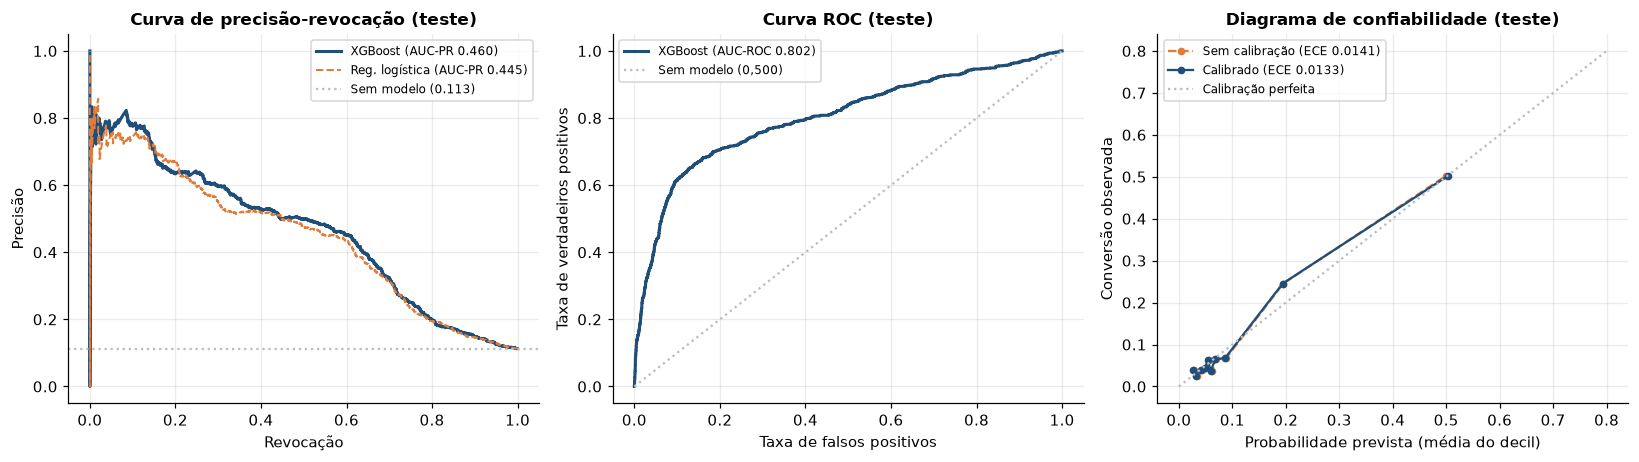

In [20]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.3))

precisao, revocacao, _ = precision_recall_curve(y_teste, score_teste)
eixos[0].plot(revocacao, precisao, color=AZUL, lw=2, label=f"XGBoost (AUC-PR {metricas_teste['AUC-PR']:.3f})")
p_rl = modelo_rl.predict_proba(X_teste)[:, 1]
pr_rl = precision_recall_curve(y_teste, p_rl)
eixos[0].plot(pr_rl[1], pr_rl[0], color=LARANJA, lw=1.3, ls="--",
              label=f"Reg. logística (AUC-PR {average_precision_score(y_teste, p_rl):.3f})")
eixos[0].axhline(y_teste.mean(), color=CINZA, ls=":", label=f"Sem modelo ({y_teste.mean():.3f})")
eixos[0].set(xlabel="Revocação", ylabel="Precisão", title="Curva de precisão-revocação (teste)")
eixos[0].legend(fontsize=8)

fpr, tpr, _ = roc_curve(y_teste, score_teste)
eixos[1].plot(fpr, tpr, color=AZUL, lw=2, label=f"XGBoost (AUC-ROC {metricas_teste['AUC-ROC']:.3f})")
eixos[1].plot([0, 1], [0, 1], color=CINZA, ls=":", label="Sem modelo (0,500)")
eixos[1].set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos",
             title="Curva ROC (teste)")
eixos[1].legend(fontsize=8)


def curva_confiabilidade(y_real, prob, n_faixas=10):
    faixas = np.array_split(np.argsort(prob, kind="stable"), n_faixas)
    return (np.array([prob[f].mean() for f in faixas]), np.array([np.asarray(y_real)[f].mean() for f in faixas]))


for rotulo, valores, cor, estilo in [("Sem calibração", score_teste, LARANJA, "--"),
                                     ("Calibrado", prob_teste, AZUL, "-")]:
    previsto, observado = curva_confiabilidade(y_teste_np, valores)
    eixos[2].plot(previsto, observado, marker="o", ms=4, color=cor, ls=estilo,
                  label=f"{rotulo} (ECE {erro_calibracao_esperado(y_teste_np, valores):.4f})")
eixos[2].plot([0, 0.8], [0, 0.8], color=CINZA, ls=":", label="Calibração perfeita")
eixos[2].set(xlabel="Probabilidade prevista (média do decil)", ylabel="Conversão observada",
             title="Diagrama de confiabilidade (teste)")
eixos[2].legend(fontsize=8)
plt.tight_layout()
salvar("fig02_curvas_teste")

### Ganho acumulado e lift por decil

A tabela responde à pergunta operacional: se a equipe atender só os primeiros decis da fila
ordenada pelo modelo, quantas conversões captura?

In [21]:
def tabela_decis(y_real, score, prob):
    df = pd.DataFrame({"y": np.asarray(y_real), "score": score, "prob": prob})
    df = df.sort_values("score", ascending=False, kind="stable").reset_index(drop=True)
    df["decil"] = np.minimum(np.arange(len(df)) * 10 // len(df) + 1, 10)
    t = df.groupby("decil").agg(leads=("y", "size"), conversoes=("y", "sum"),
                                taxa_conversao=("y", "mean"), prob_media_prevista=("prob", "mean"))
    t["lift"] = t["taxa_conversao"] / df["y"].mean()
    t["ganho_acumulado"] = t["conversoes"].cumsum() / df["y"].sum()
    return t


decis = tabela_decis(y_teste, score_teste, prob_teste)
decis.round(4)

,leads,conversoes,taxa_conversao,prob_media_prevista,lift,ganho_acumulado
decil,,,,,,
1,824,413,0.5012,0.5027,4.4483,0.4450
2,824,202,0.2451,0.1939,2.1757,0.6627
3,823,56,0.0680,0.0866,0.6039,0.7231
4,824,53,0.0643,0.0678,0.5708,0.7802
5,823,30,0.0365,0.0596,0.3235,0.8125
6,824,52,0.0631,0.0541,0.5601,0.8685
7,824,36,0.0437,0.0488,0.3877,0.9073
8,823,33,0.0401,0.0409,0.3559,0.9429
9,824,20,0.0243,0.0317,0.2154,0.9644


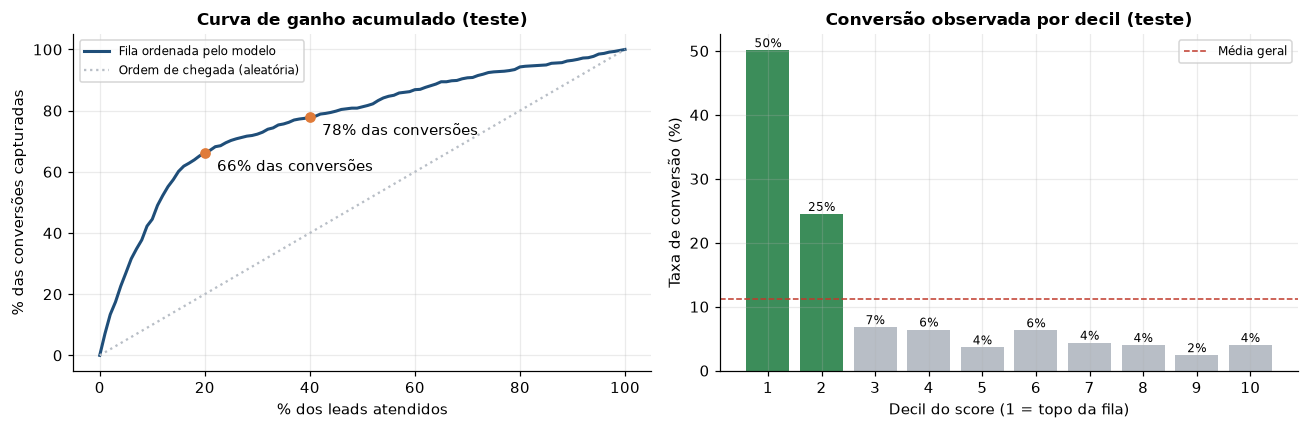

In [22]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
fracoes = np.linspace(0, 1, 101)
ganho = [0] + [revocacao_no_topo(y_teste, score_teste, f) for f in fracoes[1:]]
eixos[0].plot(fracoes * 100, np.array(ganho) * 100, color=AZUL, lw=2, label="Fila ordenada pelo modelo")
eixos[0].plot([0, 100], [0, 100], color=CINZA, ls=":", label="Ordem de chegada (aleatória)")
for f in (0.2, 0.4):
    g = revocacao_no_topo(y_teste, score_teste, f) * 100
    eixos[0].scatter([f * 100], [g], color=LARANJA, zorder=3)
    eixos[0].annotate(f"{g:.0f}% das conversões", (f * 100, g), textcoords="offset points", xytext=(8, -12))
eixos[0].set(xlabel="% dos leads atendidos", ylabel="% das conversões capturadas",
             title="Curva de ganho acumulado (teste)")
eixos[0].legend(fontsize=8)

eixos[1].bar(decis.index, decis["taxa_conversao"] * 100, color=[VERDE if l > 1 else CINZA for l in decis["lift"]])
eixos[1].axhline(y_teste.mean() * 100, color=VERMELHO, ls="--", lw=1, label="Média geral")
for d, v in zip(decis.index, decis["taxa_conversao"] * 100):
    eixos[1].text(d, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=8)
eixos[1].set(xlabel="Decil do score (1 = topo da fila)", ylabel="Taxa de conversão (%)",
             title="Conversão observada por decil (teste)", xticks=list(decis.index))
eixos[1].legend(fontsize=8)
plt.tight_layout()
salvar("fig03_ganho_decis")

### Limiar de decisão

Quando é preciso uma regra binária (abordar ou não), o limiar que maximiza o F1 é escolhido na
validação e aplicado ao teste.

In [23]:
_, prob_val_cal = pontuar(X_val)
LIMIAR_F1, _ = melhor_limiar_f1(y_val, prob_val_cal)
decisao = prob_teste >= LIMIAR_F1
limiar_teste = {
    "limiar": LIMIAR_F1,
    "precisao": precision_score(y_teste, decisao),
    "revocacao": recall_score(y_teste, decisao),
    "f1": f1_score(y_teste, decisao),
    "pct_leads_abordados": float(decisao.mean()),
}
print(f"Limiar (F1 máximo na validação): {LIMIAR_F1:.3f}")
print(f"No teste -> precisão {limiar_teste['precisao']:.3f} | revocação {limiar_teste['revocacao']:.3f} | "
      f"F1 {limiar_teste['f1']:.3f} | leads abordados {limiar_teste['pct_leads_abordados']:.1%}")

Limiar (F1 máximo na validação): 0.218
No teste -> precisão 0.465 | revocação 0.570 | F1 0.512 | leads abordados 13.8%


## 12. Interpretabilidade por valores de Shapley

Os valores de Shapley (Lundberg e Lee, 2017) decompõem cada predição em contribuições
aditivas das variáveis, na escala de log-chances. Usa-se o algoritmo exato para árvores
(TreeSHAP), disponível no próprio XGBoost. As contribuições das colunas one-hot são somadas
de volta à variável original para facilitar a leitura.

In [24]:
pre_final = modelo_final.named_steps["pre"]
clf_final = modelo_final.named_steps["clf"]
COLUNAS_MATRIZ = list(pre_final.get_feature_names_out())


def variavel_de_origem(coluna):
    for nominal in NOMINAIS:
        if coluna.startswith(nominal + "_"):
            return nominal
    return coluna


ORIGEM = [variavel_de_origem(c) for c in COLUNAS_MATRIZ]


def contribuicoes_shap(dados):
    """Valores de Shapley por variável original (log-chances) e o valor de base."""
    matriz = xgb.DMatrix(pre_final.transform(dados[PREDITORAS]), feature_names=COLUNAS_MATRIZ)
    contrib = clf_final.get_booster().predict(matriz, pred_contribs=True)
    por_variavel = pd.DataFrame(contrib[:, :-1], columns=COLUNAS_MATRIZ, index=dados.index)
    por_variavel = por_variavel.T.groupby(ORIGEM).sum().T
    return por_variavel, contrib[:, -1]


shap_teste, base_shap = contribuicoes_shap(X_teste)
# Propriedade de aditividade: base + soma das contribuições = log-chances da predição
erro_aditividade = np.abs(base_shap + shap_teste.sum(axis=1).to_numpy() - logit(score_teste)).max()
print(f"Erro máximo de aditividade: {erro_aditividade:.2e}")

importancia_shap = shap_teste.abs().mean().sort_values(ascending=False)
importancia_shap.round(4).to_frame("média de |SHAP|")

Erro máximo de aditividade: 3.58e-06


,média de |SHAP|
taxa_variacao_emprego,0.6789
canal_contato,0.1644
indice_confianca_consumidor,0.1209
mes_contato,0.1168
contato_previo,0.1130
indice_precos_consumidor,0.0860
resultado_campanha_anterior,0.0636
n_contatos_campanha,0.0621
idade,0.0488
profissao,0.0485


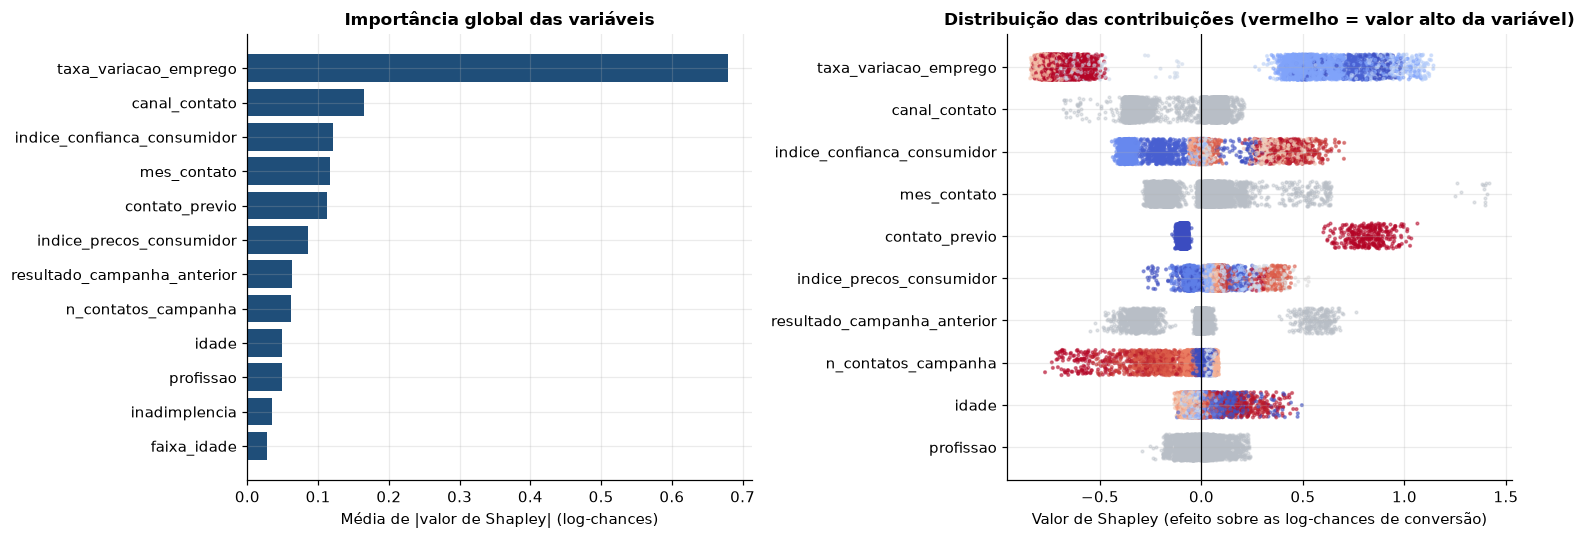

In [25]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
top = importancia_shap.head(12).iloc[::-1]
eixos[0].barh(top.index, top.values, color=AZUL)
eixos[0].set(xlabel="Média de |valor de Shapley| (log-chances)", title="Importância global das variáveis")

# Dispersão das contribuições por variável; a cor mostra o valor da variável quando numérica.
variaveis_top = list(importancia_shap.head(10).index)[::-1]
gerador_jitter = np.random.default_rng(SEMENTE)
for posicao, variavel in enumerate(variaveis_top):
    valores = shap_teste[variavel].to_numpy()
    y_jitter = posicao + gerador_jitter.uniform(-0.3, 0.3, len(valores))
    if variavel in NUMERICAS + BINARIAS:
        cor = X_teste[variavel].rank(pct=True).to_numpy()
        eixos[1].scatter(valores, y_jitter, c=cor, cmap="coolwarm", s=3, alpha=0.5)
    else:
        eixos[1].scatter(valores, y_jitter, color=CINZA, s=3, alpha=0.4)
eixos[1].axvline(0, color="black", lw=0.8)
eixos[1].set_yticks(range(len(variaveis_top)))
eixos[1].set_yticklabels(variaveis_top)
eixos[1].set(xlabel="Valor de Shapley (efeito sobre as log-chances de conversão)",
             title="Distribuição das contribuições (vermelho = valor alto da variável)")
plt.tight_layout()
salvar("fig04_shap_global")

In [26]:
# Explicação individual: o lead mais bem pontuado e um lead de score baixo no teste.
def explicar_lead(indice):
    linha = shap_teste.loc[indice].sort_values(key=np.abs, ascending=False).head(6)
    return pd.DataFrame({"valor_da_variavel": [X_teste.loc[indice, v] for v in linha.index],
                         "contribuicao_shap": linha.round(3).values}, index=linha.index)


indice_topo = X_teste.index[np.argmax(score_teste)]
indice_baixo = X_teste.index[np.argsort(score_teste)[len(score_teste) // 10]]
print(f"Lead do topo da fila: probabilidade calibrada {prob_teste[np.argmax(score_teste)]:.1%}")
print(explicar_lead(indice_topo).to_string())
print(f"\nLead do 9º decil: probabilidade calibrada {prob_teste[np.argsort(score_teste)[len(score_teste) // 10]]:.1%}")
print(explicar_lead(indice_baixo).to_string())

Lead do topo da fila: probabilidade calibrada 87.0%
                            valor_da_variavel  contribuicao_shap
taxa_variacao_emprego                    -1.7              1.086
contato_previo                              1              0.857
resultado_campanha_anterior           success              0.588
indice_confianca_consumidor             -40.3              0.466
indice_precos_consumidor               94.215              0.392
idade                                      60              0.257

Lead do 9º decil: probabilidade calibrada 2.9%
                         valor_da_variavel  contribuicao_shap
taxa_variacao_emprego                  1.1             -0.701
canal_contato                    telephone             -0.361
mes_contato                            may             -0.193
contato_previo                           0             -0.083
inadimplencia                 desconhecido             -0.081
indice_precos_consumidor            93.994              0.057


**Leitura.** O contexto macroeconômico, sobretudo a taxa de variação do emprego, domina a
importância global, seguido do canal, do mês e do histórico de contato. Isso é coerente com a
base: a conversão variou muito ao longo do período e os indicadores macroeconômicos funcionam
como marcadores desse período. O perfil declarado (profissão, idade, escolaridade) tem peso
menor. A consequência para o uso do score é examinada na seção 14.

## 13. Política de priorização e impacto no CAC

O score vira política quando se fixa a **capacidade de atendimento**: a equipe consegue
abordar uma fração dos leads e escolhe quais. Compara-se a fila ordenada pelo modelo com a
ordem de chegada (equivalente a uma escolha aleatória).

O custo de aquisição soma mídia e atendimento e divide pelas conversões:
CAC = (N x CPL + n_atendidos x custo_abordagem) / conversões.

**Atenção:** o custo por lead (R$ 20) e o custo por abordagem (R$ 8) são **premissas
ilustrativas**, pois a base não traz custos. O resultado em reais muda com as premissas; a
redução percentual do CAC depende só do lift do modelo. O dashboard permite alterar os valores.

In [27]:
CPL_PADRAO, CUSTO_ABORDAGEM_PADRAO = 20.0, 8.0


def simular_politica(y_real, score, capacidade, cpl=CPL_PADRAO, custo_abordagem=CUSTO_ABORDAGEM_PADRAO):
    n, total_conv = len(y_real), float(np.sum(y_real))
    atendidos = int(np.ceil(capacidade * n))
    conv_modelo = revocacao_no_topo(y_real, score, capacidade) * total_conv
    conv_aleatorio = capacidade * total_conv
    custo = n * cpl + atendidos * custo_abordagem
    return {"capacidade": capacidade, "leads_atendidos": atendidos,
            "conversoes_modelo": conv_modelo, "conversoes_ordem_chegada": conv_aleatorio,
            "ganho_conversoes_pct": (conv_modelo / conv_aleatorio - 1) * 100,
            "cac_modelo": custo / conv_modelo, "cac_ordem_chegada": custo / conv_aleatorio,
            "reducao_cac_pct": (1 - conv_aleatorio / conv_modelo) * 100}


politica = pd.DataFrame([simular_politica(y_teste_np, score_teste, c)
                         for c in (0.10, 0.20, 0.30, 0.40, 0.50, 0.75, 1.00)])
politica.round(2)

,capacidade,leads_atendidos,conversoes_modelo,conversoes_ordem_chegada,ganho_conversoes_pct,cac_modelo,cac_ordem_chegada,reducao_cac_pct
0,0.10,824,413.0,92.8,345.04,414.80,1846.03,77.53
1,0.20,1648,615.0,185.6,231.36,289.27,958.53,69.82
2,0.30,2471,671.0,278.4,141.02,274.94,662.67,58.51
3,0.40,3295,724.0,371.2,95.04,263.92,514.76,48.73
4,0.50,4118,754.0,464.0,62.50,262.15,426.00,38.46
5,0.75,6177,860.0,696.0,23.56,249.00,307.67,19.07
6,1.00,8236,928.0,928.0,0.00,248.50,248.50,0.00


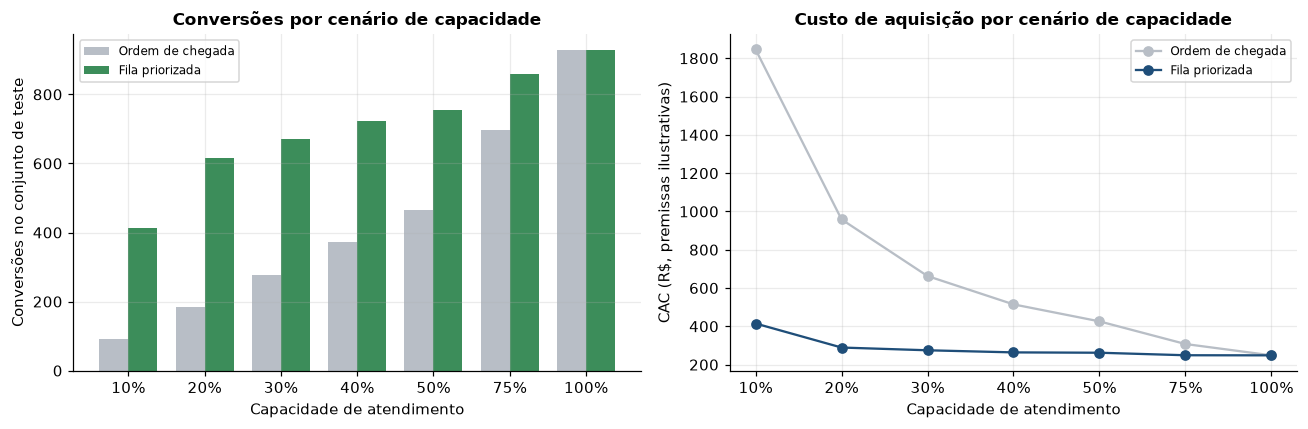

In [28]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
rotulos = [f"{c:.0%}" for c in politica["capacidade"]]
largura, posicoes = 0.38, np.arange(len(politica))
eixos[0].bar(posicoes - largura / 2, politica["conversoes_ordem_chegada"], largura, color=CINZA, label="Ordem de chegada")
eixos[0].bar(posicoes + largura / 2, politica["conversoes_modelo"], largura, color=VERDE, label="Fila priorizada")
eixos[0].set(xticks=posicoes, xticklabels=rotulos, xlabel="Capacidade de atendimento",
             ylabel="Conversões no conjunto de teste", title="Conversões por cenário de capacidade")
eixos[0].legend(fontsize=8)
eixos[1].plot(rotulos, politica["cac_ordem_chegada"], marker="o", color=CINZA, label="Ordem de chegada")
eixos[1].plot(rotulos, politica["cac_modelo"], marker="o", color=AZUL, label="Fila priorizada")
eixos[1].set(xlabel="Capacidade de atendimento", ylabel="CAC (R$, premissas ilustrativas)",
             title="Custo de aquisição por cenário de capacidade")
eixos[1].legend(fontsize=8)
plt.tight_layout()
salvar("fig05_politica_cac")

## 14. Verificação de robustez temporal e ablação

A base está em ordem cronológica (maio de 2008 a novembro de 2010) e o particionamento
aleatório mistura períodos. Em produção, o modelo sempre pontua leads **futuros**. Para medir
o quanto isso importa, o mesmo algoritmo e os mesmos hiperparâmetros são treinados nos
primeiros 80% dos registros e avaliados nos 20% finais.

In [29]:
corte = int(len(base) * 0.80)
passado, futuro = base.iloc[:corte], base.iloc[corte:]
modelo_temporal = criar_pipeline(xgb_base()).fit(passado[PREDITORAS], passado[ALVO])
score_futuro = modelo_temporal.predict_proba(futuro[PREDITORAS])[:, 1]

robustez_temporal = {
    "registros_treino": len(passado), "registros_teste": len(futuro),
    "taxa_conversao_treino": float(passado[ALVO].mean()),
    "taxa_conversao_teste": float(futuro[ALVO].mean()),
    "AUC-PR": average_precision_score(futuro[ALVO], score_futuro),
    "AUC-ROC": roc_auc_score(futuro[ALVO], score_futuro),
    "Revocação top 20%": revocacao_no_topo(futuro[ALVO], score_futuro, 0.20),
    "Lift 1º decil": revocacao_no_topo(futuro[ALVO], score_futuro, 0.10) / 0.10,
    "Brier": brier_score_loss(futuro[ALVO], score_futuro),
    "prob_media_prevista": float(score_futuro.mean()),
}
pd.Series(robustez_temporal).round(4).to_frame("partição temporal")

,partição temporal
registros_treino,32940.0000
registros_teste,8236.0000
taxa_conversao_treino,0.0638
taxa_conversao_teste,0.3083
AUC-PR,0.4712
AUC-ROC,0.6869
Revocação top 20%,0.3537
Lift 1º decil,1.5439
Brier,0.2274
prob_media_prevista,0.1420


**Leitura.** O período final tem taxa de conversão muito diferente da do período de treino,
e as variáveis macroeconômicas assumem valores que o modelo nunca viu. A capacidade de
ordenar cai em relação ao particionamento aleatório e a probabilidade prevista deixa de
refletir a taxa real. É a principal limitação do trabalho: os resultados da seção 11 são um
limite superior do desempenho em produção, e o uso real exige monitoramento de desvio e
reciclagem periódica do modelo.

### Ablação: quanto do desempenho vem do perfil do lead e quanto vem do contexto?

Os valores de Shapley mostraram que o contexto macroeconômico domina o score. Isso importa
para o uso operacional: leads que chegam no mesmo dia compartilham o mesmo contexto, então
essas variáveis não ajudam a ordenar a fila **daquele dia**. Duas verificações medem o efeito:

1. **Ablação de variáveis**: o mesmo XGBoost é treinado sem o bloco macroeconômico e, depois,
   também sem o mês do contato;
2. **AUC-ROC intracontexto**: a AUC-ROC é calculada dentro de cada grupo de leads com o mesmo
   mês e os mesmos indicadores macroeconômicos, e os grupos são combinados com peso igual ao
   número de pares convertido/não convertido. Mede a ordenação entre leads contemporâneos.

In [30]:
MACRO = ["taxa_variacao_emprego", "indice_precos_consumidor", "indice_confianca_consumidor"]
CHAVE_CONTEXTO = ["mes_contato"] + MACRO


def auc_intracontexto(dados, y_real, score):
    """AUC-ROC média dentro de grupos de mesmo contexto, ponderada pelo número de pares."""
    df = dados[CHAVE_CONTEXTO].assign(y=np.asarray(y_real), s=np.asarray(score))
    soma, pares_total, grupos_validos = 0.0, 0, 0
    for _, grupo in df.groupby(CHAVE_CONTEXTO):
        positivos = int(grupo["y"].sum())
        pares = positivos * (len(grupo) - positivos)
        if pares > 0:
            soma += roc_auc_score(grupo["y"], grupo["s"]) * pares
            pares_total += pares
            grupos_validos += 1
    return soma / pares_total, grupos_validos


def pipeline_reduzido(excluir):
    """Mesmo pré-processamento e mesmo XGBoost, sem as variáveis indicadas."""
    nominais = [c for c in NOMINAIS if c not in excluir]
    numericas = [c for c in NUMERICAS if c not in excluir]
    ordinal = Pipeline([
        ("codifica", OrdinalEncoder(categories=[ORDEM_ESCOLARIDADE, ORDEM_FAIXA],
                                    handle_unknown="use_encoded_value", unknown_value=np.nan)),
        ("imputa", SimpleImputer(strategy="median")), ("padroniza", StandardScaler())])
    pre = ColumnTransformer([
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominais),
        ("ord", ordinal, ORDINAIS), ("num", StandardScaler(), numericas),
        ("bin", "passthrough", BINARIAS)], verbose_feature_names_out=False)
    return Pipeline([("pre", pre), ("clf", xgb_base())])


conjuntos = {
    "Completo (modelo final)": [],
    "Sem bloco macroeconômico": MACRO,
    "Sem macro e sem mês (só perfil, canal e histórico)": MACRO + ["mes_contato"],
}
linhas_ablacao = []
for nome, excluir in conjuntos.items():
    if excluir:
        s = pipeline_reduzido(excluir).fit(X_treino, y_treino).predict_proba(X_teste)[:, 1]
    else:
        s = score_teste
    intra, n_grupos = auc_intracontexto(X_teste, y_teste, s)
    linhas_ablacao.append({"Conjunto de variáveis": nome, "Nº de variáveis": len(PREDITORAS) - len(excluir),
                           "AUC-PR": average_precision_score(y_teste, s),
                           "AUC-ROC": roc_auc_score(y_teste, s),
                           "Revocação top 20%": revocacao_no_topo(y_teste, s, 0.20),
                           "Lift 1º decil": revocacao_no_topo(y_teste, s, 0.10) / 0.10,
                           "AUC-ROC intracontexto": intra})
ablacao = pd.DataFrame(linhas_ablacao).set_index("Conjunto de variáveis")
print(f"Grupos de contexto com as duas classes no teste: {n_grupos}")
ablacao.round(4)

Grupos de contexto com as duas classes no teste: 25


,Nº de variáveis,AUC-PR,AUC-ROC,Revocação top 20%,Lift 1º decil,AUC-ROC intracontexto
Conjunto de variáveis,,,,,,
Completo (modelo final),17,0.4603,0.8023,0.6627,4.4504,0.5624
Sem bloco macroeconômico,14,0.4237,0.7794,0.6088,4.2996,0.5689
"Sem macro e sem mês (só perfil, canal e histórico)",13,0.3672,0.7358,0.4946,3.5560,0.5563


**Leitura.** A diferença entre a AUC-ROC global e a intracontexto do modelo completo é a
parte do desempenho que vem de saber **quando** o lead chegou, e não **quem** ele é. O modelo
sem macro e sem mês mostra o que o perfil, o canal e o histórico explicam sozinhos. A
conclusão prática é que o score serve a dois usos distintos: comparar leads de períodos
diferentes (uma base acumulada, um reaquecimento de carteira), em que o contexto ajuda, e
ordenar a fila do dia, em que o ganho é o medido pela coluna intracontexto.

### Política de priorização em cenário conservador

A simulação da seção 13 ordena uma fila única com leads de todos os períodos. O cenário
conservador abaixo aplica a capacidade **dentro de cada contexto**: em cada grupo de leads
contemporâneos, a equipe atende a mesma fração, escolhida pelo score. É a estimativa mais
próxima do ganho de ordenar a fila de um dia.

In [31]:
def revocacao_intracontexto(dados, y_real, score, fracao):
    """Conversões capturadas quando a fração superior é atendida dentro de cada contexto."""
    # sort_index: empates de score são desfeitos pela ordem original dos registros
    df = dados[CHAVE_CONTEXTO].assign(y=np.asarray(y_real), s=np.asarray(score)).sort_index()
    capturadas = 0
    for _, grupo in df.groupby(CHAVE_CONTEXTO):
        k = int(np.ceil(fracao * len(grupo)))
        capturadas += grupo.sort_values("s", ascending=False, kind="stable")["y"].iloc[:k].sum()
    return float(capturadas / df["y"].sum())


linhas_conservador = []
for c in (0.10, 0.20, 0.30, 0.40, 0.50, 0.75):
    global_ = revocacao_no_topo(y_teste, score_teste, c)
    intra_ = revocacao_intracontexto(X_teste, y_teste, score_teste, c)
    linhas_conservador.append({
        "capacidade": c, "conversoes_capturadas_fila_unica": global_,
        "conversoes_capturadas_intracontexto": intra_,
        "lift_fila_unica": global_ / c, "lift_intracontexto": intra_ / c,
        "reducao_cac_fila_unica_pct": (1 - c / global_) * 100,
        "reducao_cac_intracontexto_pct": (1 - c / intra_) * 100})
politica_conservadora = pd.DataFrame(linhas_conservador)
politica_conservadora.round(3)

,capacidade,conversoes_capturadas_fila_unica,conversoes_capturadas_intracontexto,lift_fila_unica,lift_intracontexto,reducao_cac_fila_unica_pct,reducao_cac_intracontexto_pct
0,0.10,0.445,0.156,4.450,1.562,77.530,36.000
1,0.20,0.663,0.295,3.314,1.476,69.821,32.263
2,0.30,0.723,0.419,2.410,1.397,58.510,28.432
3,0.40,0.780,0.522,1.950,1.304,48.729,23.306
4,0.50,0.812,0.608,1.625,1.216,38.462,17.730
5,0.75,0.927,0.812,1.236,1.083,19.070,7.692


**Leitura.** O ganho continua positivo em todos os cenários, mas é bem menor do que o da fila
única. Os dois números delimitam o que se pode esperar: o da fila única é o teto, válido
quando se prioriza uma base acumulada; o intracontexto é o piso, válido para a fila do dia.

## 15. Exportação dos artefatos

O dashboard e o artigo leem estes arquivos. Nada é digitado à mão.

In [32]:
joblib.dump({
    "pipeline": modelo_final, "metodo_calibracao": METODO_CALIBRACAO, "calibrador": calibrador_final,
    "preditoras": PREDITORAS, "nominais": NOMINAIS, "ordinais": ORDINAIS,
    "numericas": NUMERICAS, "binarias": BINARIAS, "limiar_f1": LIMIAR_F1,
    "mediana_pdays": rel_tratamento["mediana_pdays_contatados"],
    "p99_campaign": rel_tratamento["p99_campaign"],
}, PASTA_ARTEFATOS / "modelo_lead_scoring.joblib")

# Base completa pontuada, com a partição de cada registro
score_base, prob_base = pontuar(base)
pontuada = base.copy()
pontuada["particao"] = "treino"
pontuada.loc[X_val.index, "particao"] = "validacao"
pontuada.loc[X_teste.index, "particao"] = "teste"
pontuada["score_bruto"] = score_base
pontuada["prob_conversao"] = prob_base
pontuada.to_csv(PASTA_ARTEFATOS / "base_pontuada.csv", index=False)

shap_teste.assign(valor_base=base_shap).to_csv(PASTA_ARTEFATOS / "shap_teste.csv")

pontos_pr = np.linspace(0, len(precisao) - 1, 400).astype(int)
pontos_roc = np.linspace(0, len(fpr) - 1, 400).astype(int)
previsto_cal, observado_cal = curva_confiabilidade(y_teste_np, prob_teste)
previsto_bruto, observado_bruto = curva_confiabilidade(y_teste_np, score_teste)


def para_json(objeto):
    if isinstance(objeto, dict):
        return {str(k): para_json(v) for k, v in objeto.items()}
    if isinstance(objeto, (list, tuple, np.ndarray)):
        return [para_json(v) for v in objeto]
    if isinstance(objeto, (np.floating, float)):
        return float(objeto)
    if isinstance(objeto, (np.integer, int)):
        return int(objeto)
    return objeto


resultados = {
    "base": {"registros_brutos": len(bruto), "registros_tratados": len(base),
             "colunas_tratadas": base.shape[1], "taxa_conversao": base[ALVO].mean(),
             "razao_desbalanceamento": (base[ALVO] == 0).sum() / (base[ALVO] == 1).sum(),
             "n_preditoras": len(PREDITORAS), "n_colunas_matriz": n_colunas},
    "tratamento": rel_tratamento,
    "vif": vif.to_dict(),
    "associacao": associacao.to_dict(orient="records"),
    "particoes": particoes.to_dict(orient="index"),
    "hiperparametros": {"regressao_logistica": {"C": C_RL},
                        "floresta_aleatoria": {k.replace("clf__", ""): v for k, v in busca_rf.best_params_.items()},
                        "xgboost": PARAMS_XGB},
    "razao_chances": {"maiores": razao_chances.tail(6).to_dict(), "menores": razao_chances.head(6).to_dict()},
    "comparacao_modelos_validacao": comparacao_modelos.to_dict(orient="index"),
    "comparacao_estrategias_validacao": [
        {"algoritmo": a, "estrategia": e, **linha.to_dict()}
        for (a, e), linha in comparacao_estrategias.iterrows()],
    "modelo_final": {"algoritmo": CHAVE_FINAL[0], "estrategia": CHAVE_FINAL[1],
                     "calibracao": METODO_CALIBRACAO},
    "calibracao_validacao": comparacao_calibracao.to_dict(orient="index"),
    "teste": {"metricas": metricas_teste, "ic95": intervalos, "prevalencia": y_teste.mean(),
              "candidatos": teste_candidatos.to_dict(orient="index"), "limiar": limiar_teste},
    "decis_teste": decis.reset_index().to_dict(orient="records"),
    "shap_importancia": importancia_shap.to_dict(),
    "politica": {"cpl": CPL_PADRAO, "custo_abordagem": CUSTO_ABORDAGEM_PADRAO,
                 "cenarios": politica.to_dict(orient="records")},
    "robustez_temporal": robustez_temporal,
    "ablacao": ablacao.reset_index().to_dict(orient="records"),
    "politica_conservadora": politica_conservadora.to_dict(orient="records"),
    "n_grupos_contexto": n_grupos,
    "curvas_teste": {
        "pr": {"revocacao": revocacao[pontos_pr], "precisao": precisao[pontos_pr]},
        "roc": {"fpr": fpr[pontos_roc], "tpr": tpr[pontos_roc]},
        "confiabilidade": {"previsto_calibrado": previsto_cal, "observado_calibrado": observado_cal,
                           "previsto_bruto": previsto_bruto, "observado_bruto": observado_bruto},
    },
}
(PASTA_ARTEFATOS / "resultados.json").write_text(
    json.dumps(para_json(resultados), ensure_ascii=False, indent=2), encoding="utf-8")
print("Artefatos gravados em", PASTA_ARTEFATOS.resolve())
for arquivo in sorted(PASTA_ARTEFATOS.iterdir()):
    print(f"  {arquivo.name}  ({arquivo.stat().st_size / 1024:.0f} KB)")

Artefatos gravados em C:\Users\asafe\Downloads\Projeto_P2_Lead_Scoring\artefatos
  base_pontuada.csv  (7059 KB)
  modelo_lead_scoring.joblib  (697 KB)
  resultados.json  (68 KB)
  shap_teste.csv  (1826 KB)


## 16. Conclusões

As conclusões abaixo usam os números gerados nesta execução.

In [33]:
m, p20, p40 = metricas_teste, politica.iloc[1], politica.iloc[3]
print(f"1. É possível ordenar leads só com atributos conhecidos na entrada: AUC-PR de {m['AUC-PR']:.3f} "
      f"no teste, contra {y_teste.mean():.3f} de um modelo sem informação, e AUC-ROC de {m['AUC-ROC']:.3f}.")
print(f"2. Atendendo os 20% do topo da fila, a equipe captura {m['Revocação top 20%']:.1%} das conversões; "
      f"com 40%, captura {p40['conversoes_modelo'] / y_teste.sum():.1%}.")
print(f"3. O primeiro decil converte {decis.loc[1, 'taxa_conversao']:.1%}, um lift de {m['Lift 1º decil']:.2f} "
      f"sobre a média de {y_teste.mean():.1%}.")
print(f"4. Com capacidade de 20% e fila única, o CAC cai {p20['reducao_cac_pct']:.1f}% em relação à ordem "
      f"de chegada, sem verba adicional (teto do ganho).")
print(f"5. Após a calibração ({METODO_CALIBRACAO}), o ECE no teste é de {m['ECE']:.4f}: "
      f"o score pode ser lido como probabilidade.")
print(f"6. O contexto macroeconômico domina o score. Entre leads do mesmo contexto, a AUC-ROC é de "
      f"{ablacao['AUC-ROC intracontexto'].iloc[0]:.3f}; sem macro e sem mês, a AUC-ROC global é de "
      f"{ablacao['AUC-ROC'].iloc[2]:.3f}.")
pc20 = politica_conservadora.iloc[1]
print(f"   No cenário conservador (mesma capacidade dentro de cada contexto), os 20% do topo capturam "
      f"{pc20['conversoes_capturadas_intracontexto']:.1%} das conversões e o CAC cai "
      f"{pc20['reducao_cac_intracontexto_pct']:.1f}%.")
print(f"7. Limitação: em partição temporal a AUC-ROC cai para {robustez_temporal['AUC-ROC']:.3f} e a "
      f"AUC-PR fica em {robustez_temporal['AUC-PR']:.3f} com prevalência de "
      f"{robustez_temporal['taxa_conversao_teste']:.3f}. O modelo precisa de monitoramento e reciclagem.")

1. É possível ordenar leads só com atributos conhecidos na entrada: AUC-PR de 0.460 no teste, contra 0.113 de um modelo sem informação, e AUC-ROC de 0.802.
2. Atendendo os 20% do topo da fila, a equipe captura 66.3% das conversões; com 40%, captura 78.0%.
3. O primeiro decil converte 50.1%, um lift de 4.45 sobre a média de 11.3%.
4. Com capacidade de 20% e fila única, o CAC cai 69.8% em relação à ordem de chegada, sem verba adicional (teto do ganho).
5. Após a calibração (sigmoide), o ECE no teste é de 0.0133: o score pode ser lido como probabilidade.
6. O contexto macroeconômico domina o score. Entre leads do mesmo contexto, a AUC-ROC é de 0.562; sem macro e sem mês, a AUC-ROC global é de 0.736.
   No cenário conservador (mesma capacidade dentro de cada contexto), os 20% do topo capturam 29.5% das conversões e o CAC cai 32.3%.
7. Limitação: em partição temporal a AUC-ROC cai para 0.687 e a AUC-PR fica em 0.471 com prevalência de 0.308. O modelo precisa de monitoramento e reciclagem.
